In [30]:
import sys
import networkx as nx
import matplotlib.pyplot as plt
from pysat.solvers import Glucose4

def parse_clause(clause_str):
    tokens = clause_str.split()
    literals = []
    # print(tokens)
    for token in tokens:
        if token.startswith("~"):
            literal = int(token[1:]) + 1
            literals.append(-literal)
        elif token.isdigit():
            literal = int(token) + 1
            literals.append(literal)

    return literals

def process_input_file(file_path):
    with open(file_path, 'r') as file:
        input_text = file.readlines()
        return input_text
    
def get_formula(lines):
    formula = []
    var_map = {}
    for line in lines:
        if line.startswith("clause:"):
            clause_str = line.replace("clause:", "").strip()[:-1]
            literals = parse_clause(clause_str)
            formula.append(literals)
        elif "=>" in line:
            key = int(line.split(" => ")[0])
            val = line.split(" => ")[1].strip()
            var_map[key] = val
    return formula, var_map

def get_model(formula):
    solver = Glucose4()
    for cluase in formula:
        solver.add_clause(cluase)
    result = solver.solve()
    if result:
        return solver.get_model()
    else:
        return None
    
def visualize_cnf(cnf_formula):
    # 创建有向图
    G = nx.DiGraph()

    for clause in cnf_formula:
        if len(clause) == 1:  # 单子句
            literal = clause[0]
            G.add_node(literal)
        elif len(clause) == 2:  # 二子句
            literal1, literal2 = clause if clause[0] < 0 else clause[::-1]
            G.add_node(literal2)
            G.add_edge(-literal1, literal2)

    # 绘制图
    plt.figure(figsize=(10, 10), dpi=300)
    nx.draw(G, with_labels=True, node_size=200, font_size=8, font_color="black", font_weight="bold", arrowsize=10)
    plt.show()

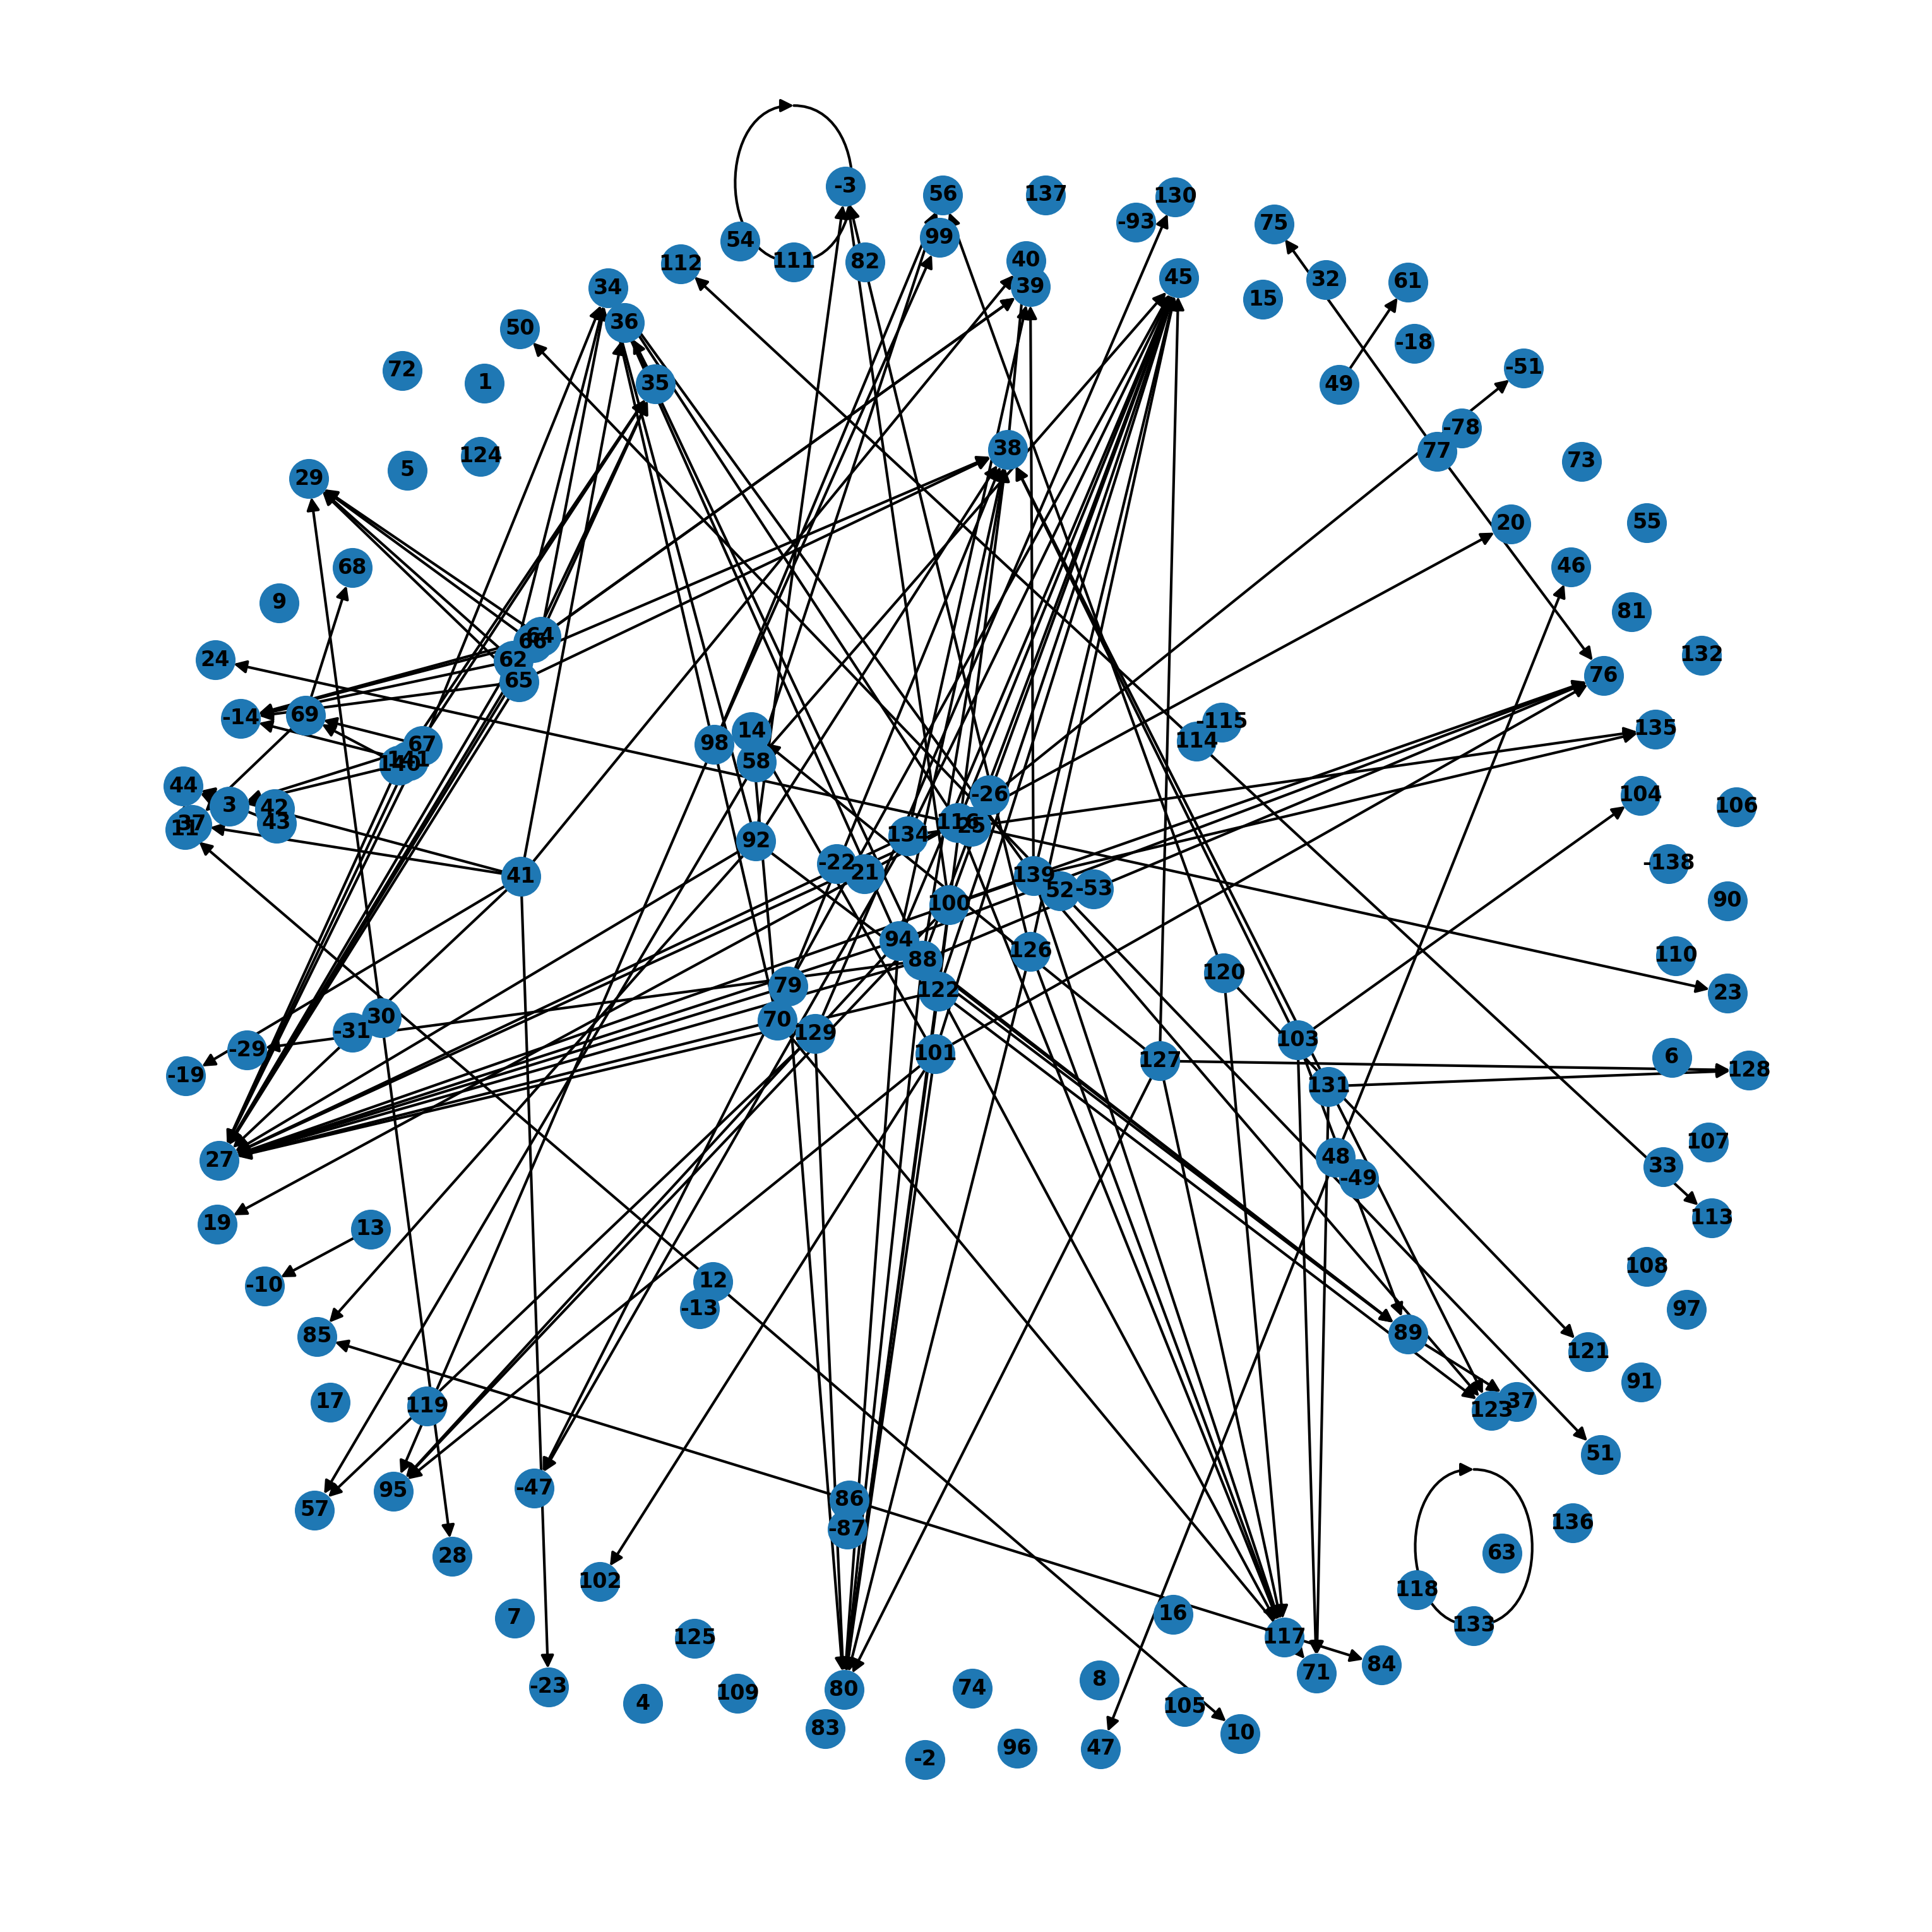

In [31]:
file_path = "../out.log"
input_text = process_input_file(file_path)
formula, var_map = get_formula(input_text)
model = get_model(formula)
visualize_cnf(formula)